# Earthquake Data Analysis
ESC 113 — Engineering Coding Project

USGS earthquake records, October 2026 (UTC), magnitude 4.0 and above.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

url = "https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime=2026-10-01&endtime=2026-11-01&minmagnitude=4&orderby=time"
raw_file = Path("earthquakes.csv")
if not raw_file.exists():
    import requests
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    raw_file.write_bytes(response.content)

df = pd.read_csv(raw_file)
print("First five records:")
print(df.head().to_string())
print("\nRecords:", len(df))
print("\nMissing values:")
print(df[["time", "latitude", "longitude", "depth", "mag", "place", "type"]].isna().sum())

First five records:
                       time  latitude  longitude    depth  mag magType  nst  gap   dmin   rms net          id                   updated                            place        type  horizontalError  depthError  magError  magNst    status locationSource magSource
0  2026-10-31T23:57:55.354Z  -13.8748   165.6627   10.000  4.8      mb   33  110  6.768  0.71  us  us7000tule  2026-11-01T00:17:06.040Z  199 km NW of Port-Olry, Vanuatu  earthquake            10.15       1.893     0.111      26  reviewed             us        us
1  2026-10-31T22:42:39.540Z  -13.8729   165.6456   10.000  5.2      mb   73   39  6.766  0.97  us  us7000tuky  2026-10-31T23:11:08.040Z  200 km NW of Port-Olry, Vanuatu  earthquake            10.63       1.787     0.041     193  reviewed             us        us
2  2026-10-31T22:15:02.901Z   33.8220   136.9854  352.449  6.0     mww  116   30  1.525  0.76  us  us7000tuku  2026-11-07T20:35:26.043Z        58 km SSE of Shima, Japan  earthquake           

## Dataset

The USGS CSV contains the event time, latitude, longitude, depth (km), magnitude, location description, and event type. The original CSV is saved separately.


In [2]:
data = df.copy()
data["time"] = pd.to_datetime(data["time"], utc=True)
for column in ["mag", "depth"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")
data = data.dropna(subset=["mag", "depth"]).copy()

def magnitude_category(m):
    if m < 4.0:
        return "Below 4"
    elif m < 5.0:
        return "4.0–4.9"
    elif m < 6.0:
        return "5.0–5.9"
    elif m < 7.0:
        return "6.0–6.9"
    else:
        return "7.0+"

def depth_category(d):
    if d < 70:
        return "Shallow"
    elif d <= 300:
        return "Intermediate"
    else:
        return "Deep"

def summary_statistics(table):
    return {"total": len(table), "average_magnitude": table["mag"].mean(),
            "largest_magnitude": table["mag"].max(), "smallest_magnitude": table["mag"].min(),
            "average_depth_km": table["depth"].mean(), "deepest_km": table["depth"].max(),
            "shallowest_km": table["depth"].min()}

data["magnitude_category"] = data["mag"].apply(magnitude_category)
data["depth_category"] = data["depth"].apply(depth_category)
print("Summary:")
for key, value in summary_statistics(data).items():
    print(key, ":", round(value, 3) if isinstance(value, float) else value)
print("\nMagnitude category counts:\n", data["magnitude_category"].value_counts())
print("\nDepth category counts:\n", data["depth_category"].value_counts())

engineering = data[(data["mag"] >= 5) & (data["depth"] < 70)]
print("\nEngineering filter: magnitude >= 5 and depth < 70 km")
print("Matching events:", len(engineering))
print("This highlights stronger earthquakes and shallower events that may warrant engineering attention; it is not a damage prediction.")
for name, index in [("Largest magnitude", data["mag"].idxmax()), ("Deepest event", data["depth"].idxmax())]:
    print("\n" + name + ":")
    print(data.loc[index, ["time", "place", "mag", "depth", "latitude", "longitude"]].to_string())

# Use a loop to count each depth category
for category in ["Shallow", "Intermediate", "Deep"]:
    print(category, "events:", (data["depth_category"] == category).sum())

Summary:
total : 1421
average_magnitude : 4.597
largest_magnitude : 7.7
smallest_magnitude : 4.0
average_depth_km : 71.803
deepest_km : 644.42
shallowest_km : 1.0

Magnitude category counts:
 magnitude_category
4.0–4.9    1201
5.0–5.9     199
6.0–6.9      19
7.0+          2
Name: count, dtype: int64

Depth category counts:
 depth_category
Shallow         1064
Intermediate     266
Deep              91
Name: count, dtype: int64

Engineering filter: magnitude >= 5 and depth < 70 km
Matching events: 193
This highlights stronger earthquakes and shallower events that may warrant engineering attention; it is not a damage prediction.

Largest magnitude:
time             2026-10-09 17:56:05.537000+00:00
place        10 km WSW of Pitaloza Arriba, Panama
mag                                           7.7
depth                                        10.0
latitude                                   7.6069
longitude                                -80.7566

Deepest event:
time         2026-10-11 12:05:

## Graphs


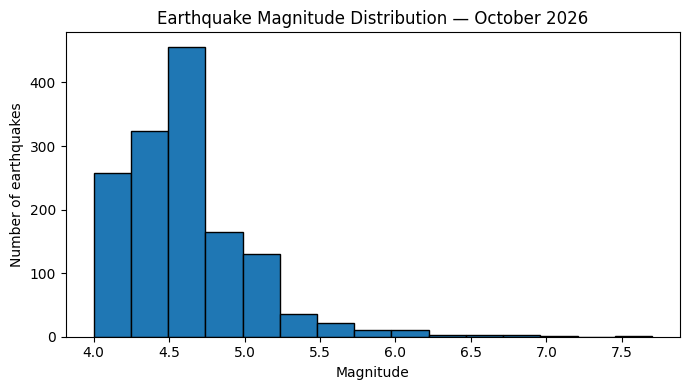

The most common magnitude category is 4.0–4.9. Smaller earthquakes were not included in the search.


In [3]:
plt.figure(figsize=(7,4))
plt.hist(data["mag"], bins=15, edgecolor="black")
plt.title("Earthquake Magnitude Distribution — October 2026")
plt.xlabel("Magnitude")
plt.ylabel("Number of earthquakes")
plt.tight_layout()
plt.savefig("01_magnitude_histogram.png", dpi=150)
plt.show()
most_mag = data["magnitude_category"].value_counts().idxmax()
print(f"The most common magnitude category is {most_mag}. Smaller earthquakes were not included in the search.")

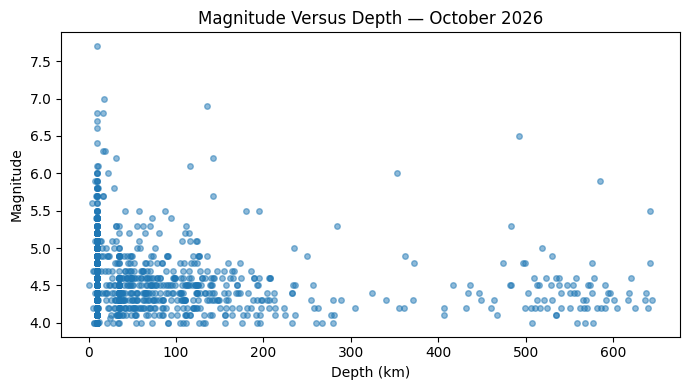

The Pearson correlation between depth and magnitude is -0.152. A value near zero means there is little linear relationship.


In [4]:
plt.figure(figsize=(7,4))
plt.scatter(data["depth"], data["mag"], alpha=0.5, s=16)
plt.title("Magnitude Versus Depth — October 2026")
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.tight_layout()
plt.savefig("02_magnitude_depth.png", dpi=150)
plt.show()
corr = data["depth"].corr(data["mag"])
print(f"The Pearson correlation between depth and magnitude is {corr:.3f}. A value near zero means there is little linear relationship.")

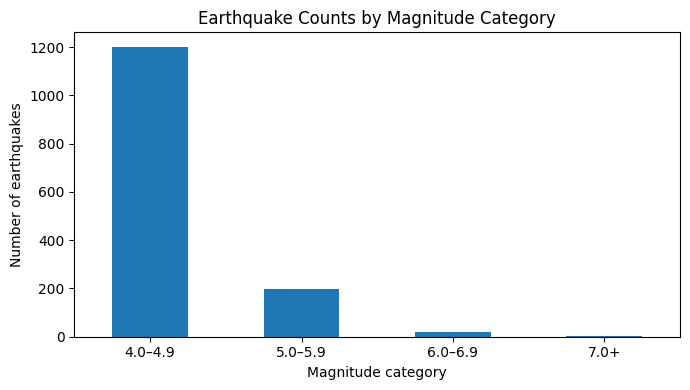

The largest bar represents 4.0–4.9 with 1201 events. The bar chart shows how the categories compare.


In [5]:
order = ["4.0–4.9", "5.0–5.9", "6.0–6.9", "7.0+"]
counts = data["magnitude_category"].value_counts().reindex(order, fill_value=0)
plt.figure(figsize=(7,4))
counts.plot(kind="bar")
plt.title("Earthquake Counts by Magnitude Category")
plt.xlabel("Magnitude category")
plt.ylabel("Number of earthquakes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("03_magnitude_categories.png", dpi=150)
plt.show()
print(f"The largest bar represents {counts.idxmax()} with {counts.max()} events. The bar chart shows how the categories compare.")

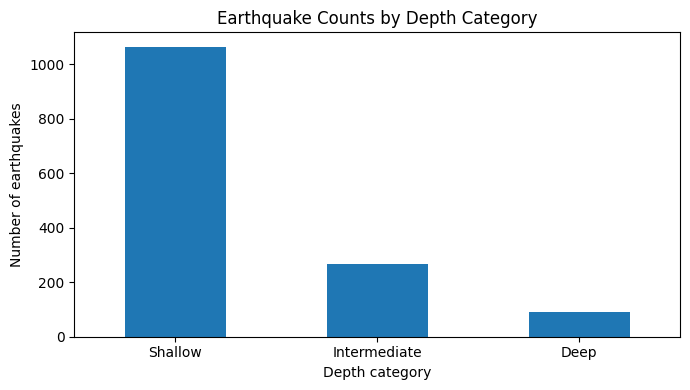

The most common depth category is Shallow with 1064 events. These groups use the depth limits given in the assignment.


In [6]:
depth_counts = data["depth_category"].value_counts().reindex(["Shallow", "Intermediate", "Deep"], fill_value=0)
plt.figure(figsize=(7,4))
depth_counts.plot(kind="bar")
plt.title("Earthquake Counts by Depth Category")
plt.xlabel("Depth category")
plt.ylabel("Number of earthquakes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("04_depth_categories.png", dpi=150)
plt.show()
print(f"The most common depth category is {depth_counts.idxmax()} with {depth_counts.max()} events. These groups use the depth limits given in the assignment.")

## Engineering interpretation


In [7]:
largest = data.loc[data["mag"].idxmax()]
shallow_high = data[(data["mag"] >= 5) & (data["depth"] < 70)]
important = shallow_high.loc[shallow_high["mag"].idxmax()] if len(shallow_high) else largest
answers = [
 f"1. The most frequent magnitude range was {most_mag}.",
 f"2. Most events were {depth_counts.idxmax().lower()} ({depth_counts.max()} of {len(data)} events).",
 f"3. The magnitude-depth correlation was {corr:.3f}. The scatter plot should be examined for any visible pattern; correlation alone does not prove a relationship.",
 f"4. A notable event was magnitude {important['mag']} near {important['place']} at depth {important['depth']} km on {important['time']}. It is selected for magnitude and relatively shallow depth, not proven damage.",
 "5. Magnitude indicates event size; depth can influence how seismic energy reaches the surface. Local ground conditions, distance, and building design also matter.",
 "6. The dataset excludes earthquakes below magnitude 4.0 and covers only one month. Catalog records may be revised.",
 "7. A more complete engineering study would include ground-motion measurements, distance to populated areas, soil conditions, structural design, and infrastructure exposure."
]
print("\n".join(answers))
with open("analysis_findings.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(answers))
print("\nSaved analysis_findings.txt for use in the report.")

1. The most frequent magnitude range was 4.0–4.9.
2. Most events were shallow (1064 of 1421 events).
3. The magnitude-depth correlation was -0.152. The scatter plot should be examined for any visible pattern; correlation alone does not prove a relationship.
4. A notable event was magnitude 7.7 near 10 km WSW of Pitaloza Arriba, Panama at depth 10.0 km on 2026-10-09 17:56:05.537000+00:00. It is selected for magnitude and relatively shallow depth, not proven damage.
5. Magnitude indicates event size; depth can influence how seismic energy reaches the surface. Local ground conditions, distance, and building design also matter.
6. The dataset excludes earthquakes below magnitude 4.0 and covers only one month. Catalog records may be revised.
7. A more complete engineering study would include ground-motion measurements, distance to populated areas, soil conditions, structural design, and infrastructure exposure.

Saved analysis_findings.txt for use in the report.


## Project report


In [8]:
import sys
import subprocess
try:
    import docx
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "python-docx", "-q"])
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

report = Document()
section = report.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.85)
section.right_margin = Inches(0.85)
normal = report.styles["Normal"]
normal.font.name = "Calibri"
normal.font.size = Pt(10)
normal.paragraph_format.space_after = Pt(5)

report.add_heading("Earthquake Data Analysis", 0)
report.add_paragraph("ESC 113 — Engineering Coding Project | October 1–31, 2026 (UTC)")
report.add_heading("Introduction", level=1)
report.add_paragraph("This project examines the frequency, magnitude, and depth of earthquakes using records from the U.S. Geological Survey (USGS). The purpose is to practice Python data analysis and consider which earthquake characteristics may matter in civil and structural engineering.")
report.add_heading("Data and Methods", level=1)
report.add_paragraph(f"The data come from the USGS Comprehensive Earthquake Catalog (ComCat), queried for October 1–31, 2026 (UTC), worldwide, with magnitude 4.0 or greater. The downloaded file contains {len(df):,} records; {len(data):,} records have usable magnitude and depth values. The original CSV was kept unchanged. The analysis uses Python and pandas for loading, statistics, classification, and filtering, and matplotlib for graphs.")
report.add_paragraph("Magnitude groups are 4.0–4.9, 5.0–5.9, 6.0–6.9, and 7.0+. Depth groups are shallow (under 70 km), intermediate (70–300 km), and deep (over 300 km). A screening filter selects events of magnitude 5.0 or higher and depth under 70 km. This filter identifies events worth examining, not events proven to have caused damage.")
report.add_heading("Results", level=1)
stats = summary_statistics(data)
report.add_paragraph(f"The analyzed catalog has {stats['total']:,} events. Mean magnitude was {stats['average_magnitude']:.2f}, with a range from {stats['smallest_magnitude']:.2f} to {stats['largest_magnitude']:.2f}. Mean depth was {stats['average_depth_km']:.1f} km, with a range from {stats['shallowest_km']:.1f} to {stats['deepest_km']:.1f} km.")
report.add_paragraph(f"The most common magnitude group was {most_mag} ({counts.max():,} events). The most common depth group was {depth_counts.idxmax().lower()} ({depth_counts.max():,} events). The engineering screening filter selected {len(engineering):,} events. The Pearson correlation between magnitude and depth was {corr:.3f}.")
report.add_paragraph(f"Largest event: magnitude {largest['mag']:.2f}, {largest['place']}, {largest['time']}, depth {largest['depth']:.1f} km. Deepest event: magnitude {data.loc[data['depth'].idxmax(),'mag']:.2f}, {data.loc[data['depth'].idxmax(),'place']}, depth {stats['deepest_km']:.1f} km.")

report.add_page_break()
report.add_heading("Figures and Observations", level=1)
for filename, heading, observation in [
    ("01_magnitude_histogram.png", "Figure 1. Magnitude distribution", f"The distribution is concentrated most strongly in the {most_mag} category. Events below magnitude 4.0 are not included in this catalog extract."),
    ("02_magnitude_depth.png", "Figure 2. Magnitude versus depth", f"The calculated linear correlation is {corr:.3f}. The scatter plot is useful for checking the spread of magnitudes across different depths, but correlation alone does not establish a physical cause."),
    ("03_magnitude_categories.png", "Figure 3. Magnitude categories", f"The largest group is {most_mag}, with {counts.max():,} earthquakes. The remaining groups have counts of " + ", ".join(f"{k}: {v:,}" for k,v in counts.items() if k != most_mag) + "."),
    ("04_depth_categories.png", "Figure 4. Depth categories", f"The {depth_counts.idxmax().lower()} category contains {depth_counts.max():,} events. Counts for all groups are " + ", ".join(f"{k.lower()}: {v:,}" for k,v in depth_counts.items()) + ".")
]:
    report.add_heading(heading, level=2)
    report.add_picture(filename, width=Inches(3.45))
    report.add_paragraph(observation)

report.add_page_break()
report.add_heading("Engineering Interpretation", level=1)
report.add_paragraph(f"The magnitude range occurring most often was {most_mag}, and most earthquakes were {depth_counts.idxmax().lower()}. The magnitude–depth correlation was {corr:.3f}; the scatter plot and this statistic should be considered together rather than treating the correlation as proof of a strong relationship.")
report.add_paragraph(f"One event worth further engineering attention was the magnitude {important['mag']:.2f} earthquake near {important['place']}, at {important['depth']:.1f} km depth. It was selected because it meets a magnitude-and-depth screening criterion. The dataset alone cannot establish how much ground shaking or structural damage occurred.")
report.add_paragraph("Magnitude describes the size of an earthquake, while depth affects the distance seismic waves travel before reaching the surface. Engineering impacts also depend on distance from the fault, soil conditions, the frequency content and duration of shaking, and the design and condition of buildings, bridges, and other infrastructure.")
report.add_heading("Limitations and Additional Data", level=1)
report.add_paragraph("This analysis covers only one month and excludes events below magnitude 4.0. Detection, reporting, and catalog revisions can also affect the data. Worldwide event counts do not directly measure risk to any specific city or structure.")
report.add_paragraph("A more complete study would add recorded ground accelerations, distance to exposed communities, local soil and geologic information, building inventories, design standards, and observed damage. Those variables would help connect earthquake characteristics to structural performance.")
report.add_heading("Conclusion", level=1)
report.add_paragraph(f"In this October 2026 dataset, the most frequent magnitude group was {most_mag}, and the most frequent depth group was {depth_counts.idxmax().lower()}. Python made it possible to summarize and visualize the catalog consistently. The results are a useful first screening step, but magnitude and depth alone are insufficient to predict damage.")
report.add_heading("Data Source", level=1)
report.add_paragraph("USGS Earthquake Catalog (ComCat), FDSN Event API: " + url)
report.save("Project_Report.docx")
print("Saved Project_Report.docx")


Saved Project_Report.docx
